In [1]:
import gensim
import pandas as pd
import numpy as np
from keras import layers
from keras import models
from gensim.models import Word2Vec
from nltk.tokenize import sent_tokenize
from nltk.tokenize import word_tokenize
from keras.preprocessing.text import Tokenizer
from sklearn.model_selection import train_test_split
from keras.preprocessing.sequence import pad_sequences

In [2]:
import re
from nltk.corpus import stopwords
from nltk.stem.wordnet import WordNetLemmatizer

In [3]:
def clean_text(text):
    lem = WordNetLemmatizer()
    stop_words = stopwords.words("english")
    
    text = text.replace(".", "")
    #replace date
    text = re.sub(r"\d{1,2}(-|/)\d{1,2}(-|/)\d{1,4}", " <date> ", text)
    #replace article tiltle, author, etc...
    text = re.sub(r"\"([a-zA-Z0-9\s.,()':!?/-])+\"", " <article> ", text)
    #replace price
    text = re.sub(r"\$([0-9,])+", " <price> ", text)
    #replace number
    text = re.sub(r"([0-9\.])+", " <nbr> ", text)
    #replace link
    text = re.sub(r'http\S+', "<URL>", text)
    text = re.sub('\&', " and ", text)

    text = re.sub("\'s", " ", text)
    text = re.sub(" whats ", " what is ", text, flags=re.IGNORECASE)
    text = re.sub("\'ve", " have ", text)
    text = re.sub("can't", "can not", text)
    text = re.sub("n't", " not ", text)
    text = re.sub("i'm", "i am", text, flags=re.IGNORECASE)
    text = re.sub("\'re", " are ", text)
    text = re.sub("\'d", " would ", text)
    text = re.sub("\'ll", " will ", text)
    text = re.sub("e\.g\.", " eg ", text, flags=re.IGNORECASE)
    text = re.sub("b\.g\.", " bg ", text, flags=re.IGNORECASE)
    
    text = text.replace("%", " percent ")
    text = text.replace("(", " <open> ")
    text = text.replace(")", " <close> ")
    text = text.replace("?", " <qtag> ")
    text = text.replace("\n"," ")
    text = text.replace("/", " / ")
    text = text.replace(",", "")
    text = text.replace(";", "")
    text = text.replace("'", "")
    text = text.replace("!", "")
    text = text.replace(":", "")
    text = text.replace("[", "")
    text = text.replace("]", "")
    text = text.replace("_", " ")
    text = text.replace("*", "")
    text = text.lower()
    
    text_list = [lem.lemmatize(i) for i in word_tokenize(text) if not i in stop_words and len(i)>2 ]
    text = " ".join(text_list)

    return text

In [5]:
train_df = pd.read_csv("train.csv")
copy_train_df = train_df.copy()
copy_train_df.drop(["id", "discourse_id", "discourse_start", "discourse_end", "discourse_type_num", "predictionstring"], axis=1, inplace=True)

In [6]:
copy_train_df.discourse_text = copy_train_df.discourse_text.apply(clean_text)

In [7]:
corpus = copy_train_df.discourse_text.apply(lambda x: [word for word in word_tokenize(x)])

In [8]:
tk = Tokenizer()
tk.fit_on_texts(copy_train_df.discourse_text)

In [9]:
# Word2Vec Parameters 
dimension = 300
window = 8
max_length = int(np.quantile([len(doc) for doc in corpus], 0.75))
vocab_size = len(list(tk.word_index.items()))

In [10]:
print(max_length)

28


In [11]:
modele = Word2Vec(corpus, vector_size=dimension, window=window)

In [12]:
words = modele.wv

In [13]:
embedding = np.zeros((vocab_size+1, dimension))
for word,idx in tk.word_index.items():
    try:
        embedding[idx] =  words[word]
    except:
        pass

In [14]:
vocab={}
for word,idx in tk.word_index.items():
    try:
        vocab[f"{word}"] =  np.mean(words[word])
    except:
        vocab[f"{word}"] =  0

In [15]:
import os

In [18]:
drs = os.listdir("train")
with open(f"train/{drs[0]}", "r") as file:
    text = file.read()
    sentences = sent_tokenize(text)
    text_list = []
    for sent in sentences:
        sent = clean_text(sent)
        liste = []
        for word in word_tokenize(sent):
            try:
                liste.append(vocab[word])
            except:
                liste.append(0)
        text_list.append(liste)

In [19]:
for sent in text_list:
    maxlen = max([len(i) for i in text_list])
    if len(sent)<maxlen:
        i = maxlen-len(sent)
        sent.extend([0]*i)

In [20]:
print([len(i) for i in text_list])

[19, 19, 19, 19, 19, 19, 19, 19, 19, 19, 19, 19, 19, 19]


In [21]:
text_list = np.array(text_list)

In [22]:
import matplotlib.pyplot as plt

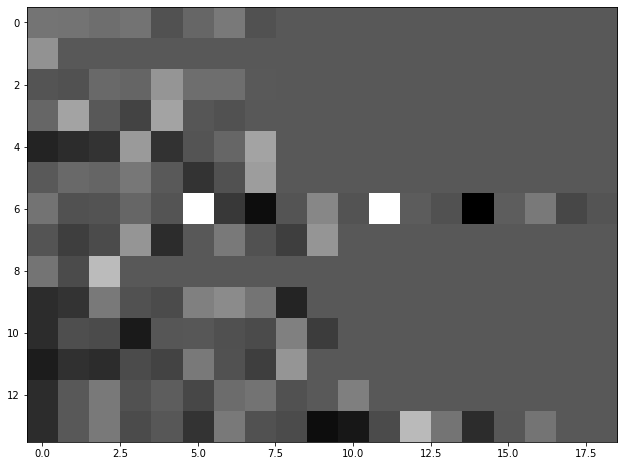

In [23]:
plt.figure(figsize=(12,8))
plt.imshow(text_list, cmap="gray")

In [51]:
X_train, X_test, y_train, y_test = train_test_split(copy_train_df.discourse_text, copy_train_df.discourse_type, test_size=0.2, random_state=123)

In [52]:
seqTrain = tk.texts_to_sequences(X_train)
padTrain = pad_sequences(seqTrain, maxlen=max_length, padding='post')

In [14]:
def attention_layer(inputs, neurons):
    x = layers.Permute((2,1))(inputs)
    x = layers.Dense(neurons, activation="softmax")(x)
    x = layers.Permute((2,1), name="attention")(x)
    x = layers.multiply([inputs, x])
    return x

In [53]:
x_in = layers.Input(shape=(max_length,))

x = layers.Embedding(input_dim=embedding.shape[0],  
                     output_dim=embedding.shape[1], 
                     weights=[embedding],
                     input_length=max_length, trainable=False)(x_in)

x = attention_layer(x, neurons=max_length)
x = layers.Bidirectional(layers.LSTM(units=max_length, dropout=0.2,return_sequences=True))(x)
x = layers.Bidirectional(layers.LSTM(units=max_length, dropout=0.2,return_sequences=True))(x)
x = layers.Bidirectional(layers.LSTM(units=max_length, dropout=0.2))(x)
x = layers.Dense(64, activation='relu')(x)
y_out = layers.Dense(7, activation='softmax')(x)

model = models.Model(x_in, y_out)
model.compile(loss='sparse_categorical_crossentropy',
              optimizer='adam', metrics=['accuracy'])

model.summary()

In [54]:
dic_y_mapping = {n:label for n,label in 
                 enumerate(np.unique(y_train))}
inverse_dic = {v:k for k,v in dic_y_mapping.items()}
y_train = np.array([inverse_dic[y] for y in y_train])

In [ ]:
training = model.fit(x=padTrain, y=y_train, batch_size=256, 
                     epochs=15, shuffle=True, verbose=1, 
                     validation_split=0.3)

In [18]:
import matplotlib.pyplot as plt
metrics = [k for k in training.history.keys() if ("loss" not in k) and ("val" not in k)]
fig, ax = plt.subplots(nrows=1, ncols=2, sharey=True)
ax[0].set(title="Training")
ax11 = ax[0].twinx()
ax[0].plot(training.history['loss'], color='black')
ax[0].set_xlabel('Epochs')
ax[0].set_ylabel('Loss', color='black')
for metric in metrics:
    ax11.plot(training.history[metric], label=metric)
ax11.set_ylabel("Score", color='steelblue')
ax11.legend()
ax[1].set(title="Validation")
ax22 = ax[1].twinx()
ax[1].plot(training.history['val_loss'], color='black')
ax[1].set_xlabel('Epochs')
ax[1].set_ylabel('Loss', color='black')
for metric in metrics:
     ax22.plot(training.history['val_'+metric], label=metric)
ax22.set_ylabel("Score", color="steelblue")
plt.show()

In [19]:
seqTest = tk.texts_to_sequences(X_test)
padTest = pad_sequences(seqTest, maxlen=max_length, padding='post')

In [20]:
predicted_prob = model.predict(padTest)
predicted = [dic_y_mapping[np.argmax(pred)] for pred in predicted_prob]

In [21]:
from sklearn.metrics import classification_report

In [22]:
print(classification_report(y_test, predicted))

In [23]:
import os

In [24]:
dirs = os.listdir("../input/feedback-prize-2021/test")
prediction = {"id":[], "class":[], "predictionstring":[]}
for dr in dirs:
    print(f"file {dr}")
    with open(f"../input/feedback-prize-2021/test/{dr}", "r") as file:
        text = file.read()
        sentences = sent_tokenize(text)
        prediction_string = []
        old_class_pred = None
        level=0
        for count,sentence in enumerate(sentences):
            c_sentence = clean_text(sentence)
            seq = tk.texts_to_sequences([c_sentence])
            pad = pad_sequences(seq, maxlen=max_length, padding='post')
            predicted_prob = model.predict(pad)
            class_pred = dic_y_mapping[np.argmax(predicted_prob[0])]
                
            if old_class_pred:
                if old_class_pred!=class_pred or count+1==len(sentences):
                    if count+1==len(sentences):
                        prediction_string.extend([str(level+i) for i in range(len(sentence.split()))])
                        
                    prediction["id"].append(dr.replace(".txt", ""))
                    prediction["class"].append(old_class_pred)
                    prediction["predictionstring"].append(" ".join(prediction_string))
                    prediction_string.clear()
                prediction_string.extend([str(level+i) for i in range(len(sentence.split()))])
            else:
                prediction_string.extend([str(i) for i in range(len(sentence.split()))])
            old_class_pred = class_pred
            level += len(sentence.split())

In [25]:
submission = pd.DataFrame(prediction)
submission.head(20)

In [ ]:
submission = pd.DataFrame(prediction)
submission.head(20)

In [ ]:
submission.predictionstring[7]

In [ ]:
submission.to_csv("submission.csv", index=False)